# ECE441 — Lab 3: EEG analysis

pre-lab: 
-import all necessary library
-ensure all file worked
-MNE package worked


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from IPython.display import display

DATA_DIR = Path.cwd()
FS = 250  # Hz, specified in the third line of both recording files
CHANNEL_NAMES = ["FP1", "FP2", "C3", "C4", "P7", "P8", "O1", "O2"]

print("Working folder:", DATA_DIR)
print("MNE version:", mne.__version__)


Working folder: [project directory]
MNE version: 1.13.2


## Step 1 — Load the recordings with pandas


The handout specifies the electrode order as FP1, FP2, C3, C4, P7, P8, O1, O2.

So I first load data from both RecA and RecB. First 4 rows has been skipped with range throuch columns 2 to 9 (8 channels in total). 

In [11]:
df_a = pd.read_csv(

    "RecA.txt",
    header = 4,
    index_col = False,
    usecols = range(1,9)
)


df_a.head()

,EXG Channel 0,EXG Channel 1,EXG Channel 2,EXG Channel 3,EXG Channel 4,EXG Channel 5,EXG Channel 6,EXG Channel 7
0,25020.498040,35148.676950,-187500.022352,67180.067859,4684.791527,-5312.003829,6701.187098,32121.580198
1,25012.652577,35135.109441,-187500.022352,67119.516983,4675.560257,-5286.008750,6705.903316,32122.563675
2,25007.154048,35125.162914,-187500.022352,67212.947275,4667.133649,-5240.724115,6721.616593,32163.780292
3,25014.686586,35137.501077,-187500.022352,67286.372755,4681.148193,-5250.514180,6725.282279,32180.499396
4,25034.132604,35149.727482,-187500.022352,67217.551734,4693.173432,-5289.808546,6718.800273,32157.499451


In [12]:
df_b = pd.read_csv(

    "RecB.txt",
    header = 4,
    index_col = False,
    usecols = range(1,9)
)

df_b.head()


,EXG Channel 0,EXG Channel 1,EXG Channel 2,EXG Channel 3,EXG Channel 4,EXG Channel 5,EXG Channel 6,EXG Channel 7
0,21010.036291,32128.866867,-187500.022352,-187500.022352,1498.930335,-10385.939227,-2699.375474,34100.849521
1,21000.469744,32118.003919,-187500.022352,-187500.022352,1486.346303,-10354.937357,-2706.036294,34131.516115
2,21000.380337,32114.204122,-187500.022352,-187500.022352,1489.877878,-10386.878000,-2713.926460,34134.488897
3,21000.581503,32117.758050,-187500.022352,-187500.022352,1496.315181,-10433.928422,-2720.341411,34098.010850
4,20994.188904,32107.409192,-187500.022352,-187500.022352,1483.395873,-10394.879925,-2715.133454,34107.756210


In [ ]:
#check the size of RecA data (6401 samples, 8 channels).

df_b.shape

(6401, 8)

Then I set the name for all eight EEG channel columns.

In [14]:
channel_names = ["FP1", "FP2", "C3", "C4", "P7", "P8", "O1", "O2"]

df_a.columns = channel_names
df_b.columns = channel_names

display(df_a.head())
display(df_b.head())

,FP1,FP2,C3,C4,P7,P8,O1,O2
0,25020.498040,35148.676950,-187500.022352,67180.067859,4684.791527,-5312.003829,6701.187098,32121.580198
1,25012.652577,35135.109441,-187500.022352,67119.516983,4675.560257,-5286.008750,6705.903316,32122.563675
2,25007.154048,35125.162914,-187500.022352,67212.947275,4667.133649,-5240.724115,6721.616593,32163.780292
3,25014.686586,35137.501077,-187500.022352,67286.372755,4681.148193,-5250.514180,6725.282279,32180.499396
4,25034.132604,35149.727482,-187500.022352,67217.551734,4693.173432,-5289.808546,6718.800273,32157.499451


,FP1,FP2,C3,C4,P7,P8,O1,O2
0,21010.036291,32128.866867,-187500.022352,-187500.022352,1498.930335,-10385.939227,-2699.375474,34100.849521
1,21000.469744,32118.003919,-187500.022352,-187500.022352,1486.346303,-10354.937357,-2706.036294,34131.516115
2,21000.380337,32114.204122,-187500.022352,-187500.022352,1489.877878,-10386.878000,-2713.926460,34134.488897
3,21000.581503,32117.758050,-187500.022352,-187500.022352,1496.315181,-10433.928422,-2720.341411,34098.010850
4,20994.188904,32107.409192,-187500.022352,-187500.022352,1483.395873,-10394.879925,-2715.133454,34107.756210


## Step 2 — Create MNE RawArray objects

prepares the data for MNE: 

- transpose data to samples x channels
- convert microvoltes to volts


In [15]:
data_a = df_a.to_numpy().T * 1e-6
data_b = df_b.to_numpy().T * 1e-6

print("RecA:", data_a.shape)
print("RecB:", data_b.shape)

RecA: (8, 6217)
RecB: (8, 6401)


In [ ]:
#create info instance
info = mne.create_info(
    ch_names = channel_names,
    sfreq = 250,  #sample rate = 250 samples per second
    ch_types = ['eeg'] * 8
)

#create raw objects and save data into variables
raw_a = mne.io.RawArray(data_a, info.copy())
raw_b = mne.io.RawArray(data_b, info.copy())

Creating RawArray with float64 data, n_channels=8, n_times=6217
    Range : 0 ... 6216 =      0.000 ...    24.864 secs
Ready.
Creating RawArray with float64 data, n_channels=8, n_times=6401
    Range : 0 ... 6400 =      0.000 ...    25.600 secs
Ready.


In [ ]:
#provide electrode positions -> create montage coordinates
montage = mne.channels.read_custom_montage(
    "electrode_positions_8channel.sfp"
)

#map montage coordinates to my variables
raw_a.set_montage(montage)
raw_b.set_montage(montage)

print(raw_a)
print(raw_b)

<RawArray | 8 x 6217 (24.9 s), ~403 KiB, data loaded>
<RawArray | 8 x 6401 (25.6 s), ~415 KiB, data loaded>


[temporary path]:6: RuntimeWarning: Fiducial point nasion not found, assuming identity unknown to head transformation
  raw_a.set_montage(montage)
[temporary path]:7: RuntimeWarning: Fiducial point nasion not found, assuming identity unknown to head transformation
  raw_b.set_montage(montage)


## Step 3 — Apply bandpass filter from 0.1 to 100 Hz

1. visiualize the data using plot method from raw object.

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


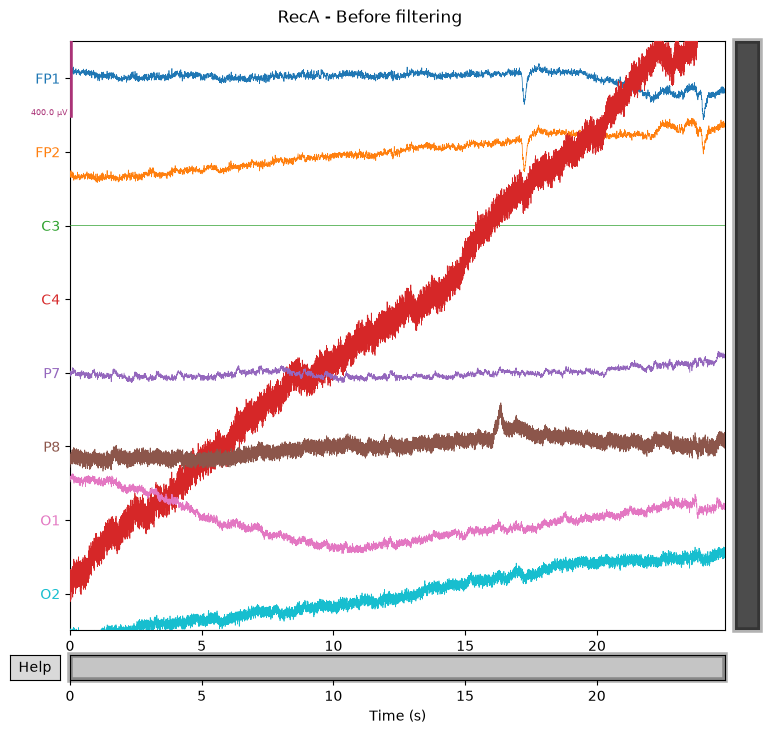

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


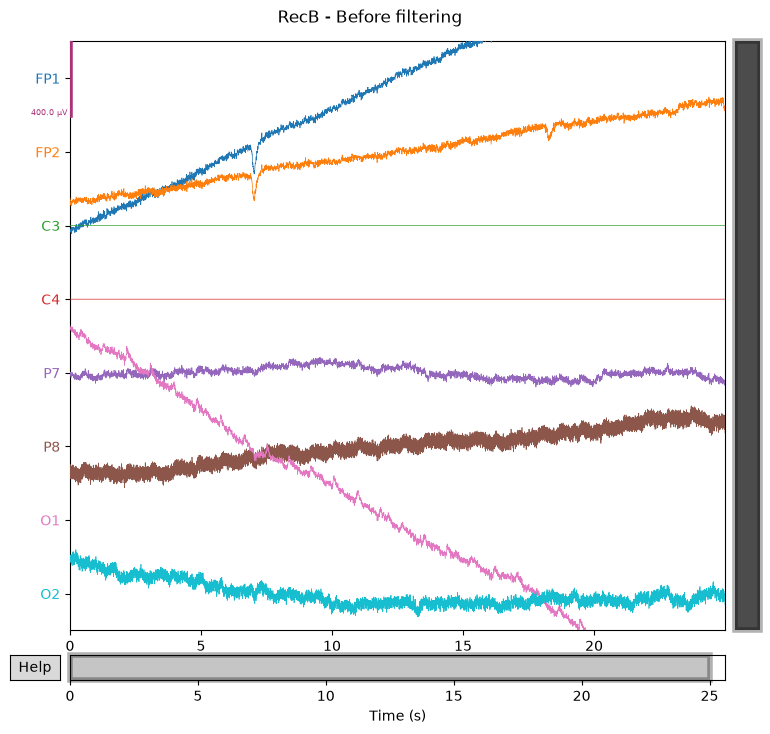

In [27]:
mne.viz.set_browser_backend("matplotlib")

channel_colors = {
    "FP1": "tab:blue",
    "FP2": "tab:orange",
    "C3": "tab:green",
    "C4": "tab:red",
    "P7": "tab:purple",
    "P8": "tab:brown",
    "O1": "tab:pink",
    "O2": "tab:cyan",
}
plots = [
    (raw_a, "RecA - Before filtering"),
    (raw_b, "RecB - Before filtering"),
]

for recording, title in plots:
    fig = recording.plot(
        duration=25, #display the whole recording
        scalings=dict(eeg=200e-6),  #sets EEG display to 200 uV -> 400 uV ptp
        clipping=None,
        color=channel_colors,
        title=title,
        show=False
    )

    fig.subplots_adjust(top=0.88)
    fig.suptitle(title, fontsize=12, y=0.92)
    plt.show()


In [19]:
#apply 0.1Hz to 100Hz bandpass filter and 60Hz notch filter

filtered_a = raw_a.copy()
filtered_b = raw_b.copy()

filtered_a.filter(l_freq=0.1, h_freq=100)
filtered_b.filter(l_freq=0.1, h_freq=100)

filtered_a.notch_filter(freqs=60)
filtered_b.notch_filter(freqs=60)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 8251 samples (33.004 s)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper pa

[temporary path]:6: RuntimeWarning: filter_length (8251) is longer than the signal (6217), distortion is likely. Reduce filter length or filter a longer signal.
  filtered_a.filter(l_freq=0.1, h_freq=100)
[temporary path]:7: RuntimeWarning: filter_length (8251) is longer than the signal (6401), distortion is likely. Reduce filter length or filter a longer signal.
  filtered_b.filter(l_freq=0.1, h_freq=100)


<RawArray | 8 x 6401 (25.6 s), ~415 KiB, data loaded>

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


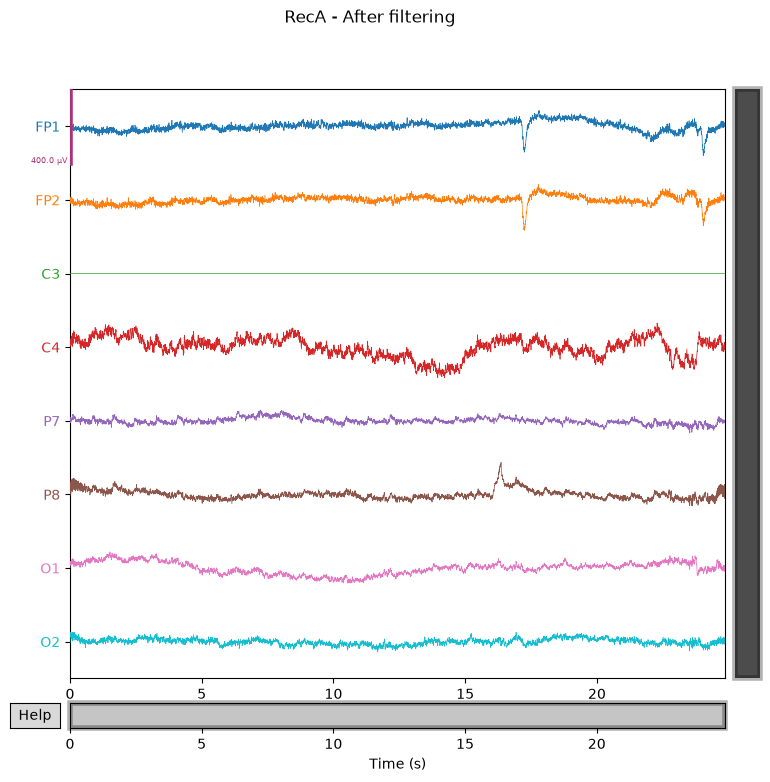

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


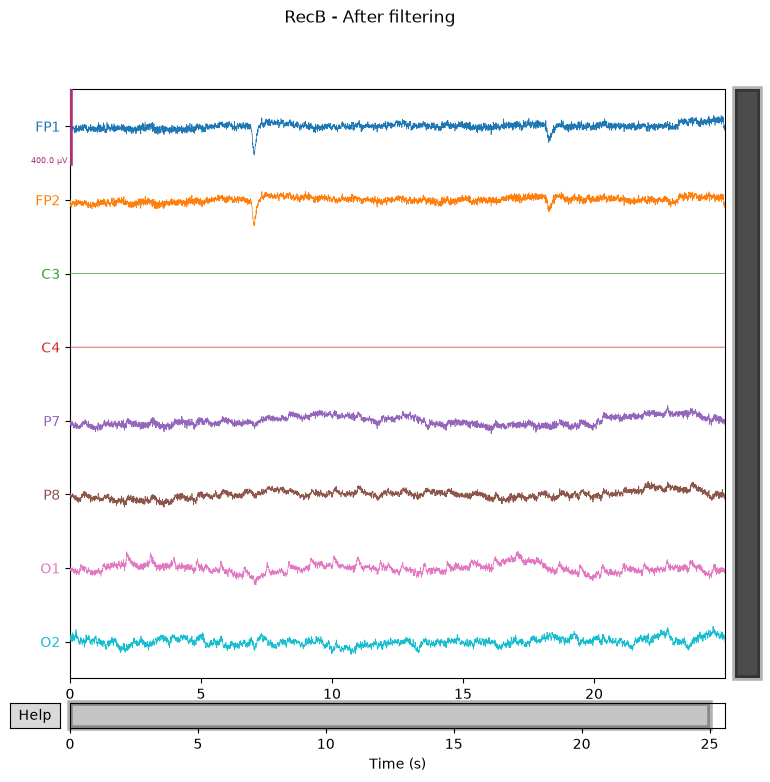

In [28]:
#generate filltered plots


plots = [
    (filtered_a, "RecA - After filtering"),
    (filtered_b, "RecB - After filtering"),
]

for recording, title in plots:
    fig = recording.plot(
        duration=25,
        scalings=dict(eeg=200e-6),
        clipping=None,
        color=channel_colors,
        title=title,
        show=False
    )

    
    fig.subplots_adjust(top=0.88)
    fig.suptitle(title, fontsize=12, y=0.98)

    plt.show()

## Step 4 — Inspect and mark bad channels

- reject bad channels (channel 3 & 4)

In [29]:
#mark the bad channels

bad_channels = ["C3", "C4"]

filtered_a.info["bads"] = bad_channels.copy()
filtered_b.info["bads"] = bad_channels.copy()

print("RecA bad channels:", filtered_a.info["bads"])
print("RecB bad channels:", filtered_b.info["bads"])

RecA bad channels: ['C3', 'C4']
RecB bad channels: ['C3', 'C4']


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


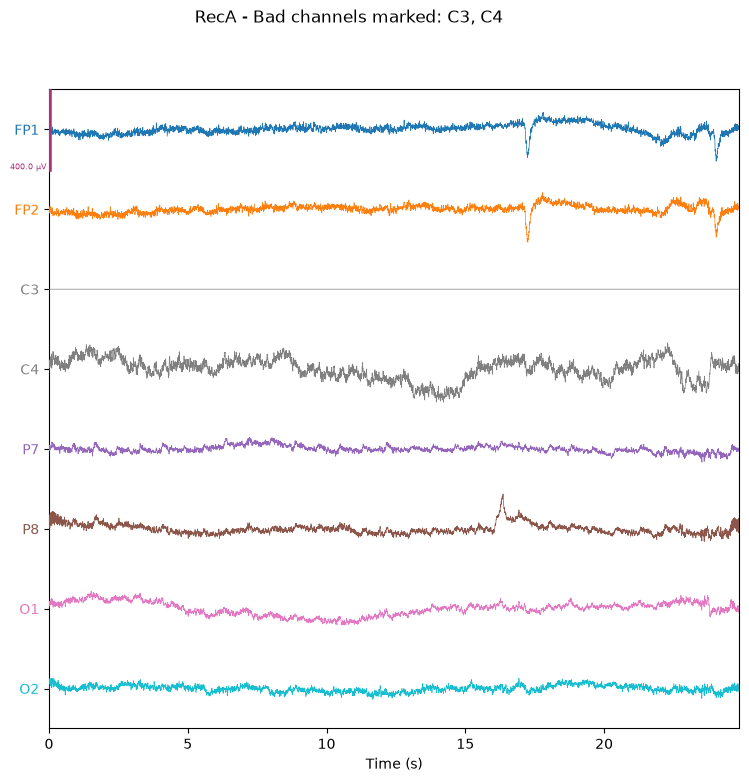

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


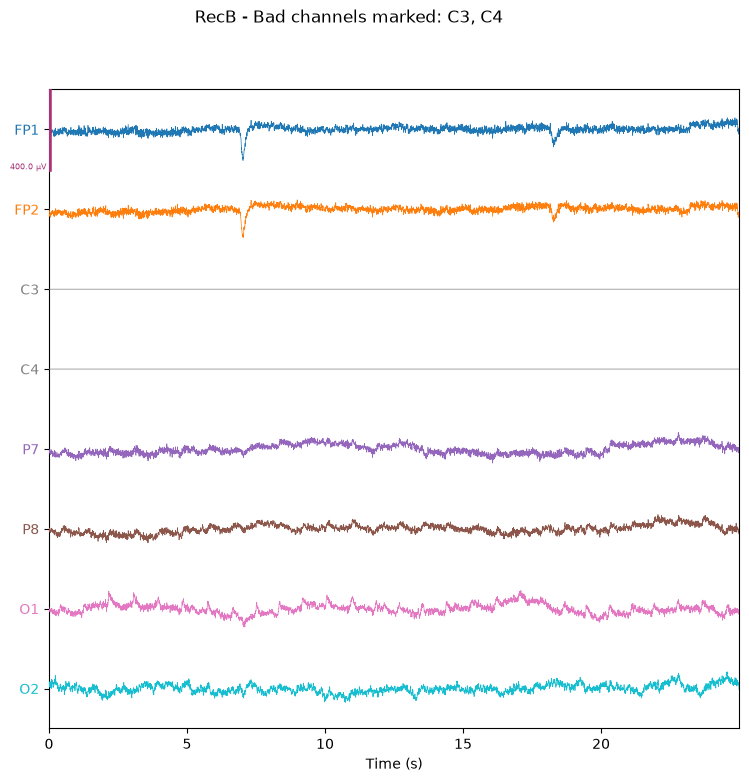

In [30]:
plots = [
    (filtered_a, "RecA - Bad channels marked: C3, C4"),
    (filtered_b, "RecB - Bad channels marked: C3, C4"),
]


for recording, title in plots:
    fig = recording.plot(
        duration=25,
        scalings=dict(eeg=200e-6),
        clipping=None,
        color=channel_colors,
        bad_color="gray",
        title=title,
        show_scrollbars=False,
        show=False
    )

    fig.subplots_adjust(top=0.88)
    fig.suptitle(title, fontsize=12, y=0.98)

    plt.show()


## Step 5 — Plot the spectral response for each channel

- method: compute_psd: spectral analysis of electrodes
- Fmin = 1Hz, Fmax = 30Hz for illustrate
- raw.compute_psd(arguments).plot(): plot power spectrum

In [ ]:
#compute psd
psd_a = filtered_a.compute_psd(
    fmin=1,
    fmax=30,
    picks="eeg",
    exclude="bads"
)

psd_b = filtered_b.compute_psd(
    fmin=1,
    fmax=30,
    picks="eeg",
    exclude="bads"
)

Effective window size : 8.192 (s)
Effective window size : 8.192 (s)


Plotting power spectral density (dB=True).


[temporary path]:15: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(top=0.85)


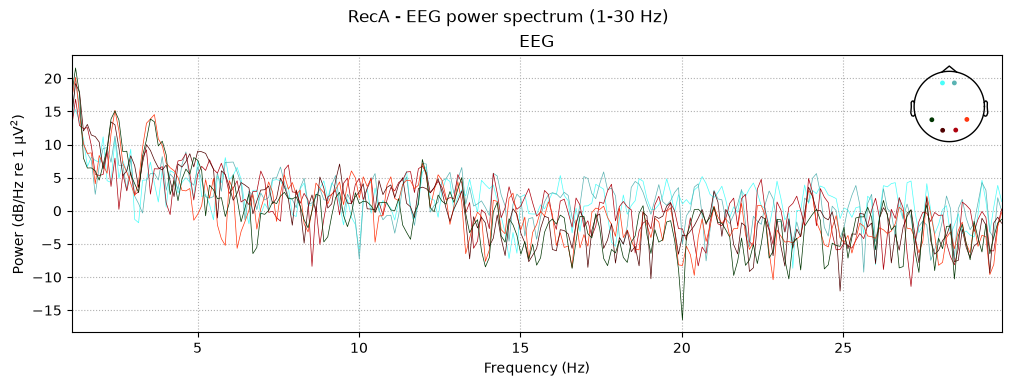

Plotting power spectral density (dB=True).


[temporary path]:15: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(top=0.85)


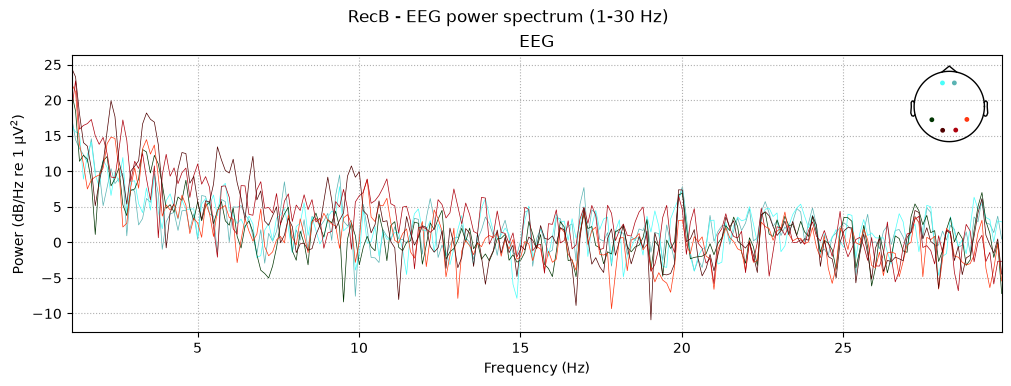

In [39]:
plots = [
    (psd_a, " RecA - EEG power spectrum (1-30 Hz)"),
    (psd_b, " RecB - EEG power spectrum (1-30 Hz)"),
]

for spectrum, title in plots:
    fig = spectrum.plot(
        average=False,
        spatial_colors=True,
        dB=True,
        alpha=1,
        show=False
    )

    fig.subplots_adjust(top=0.85)
    fig.suptitle(title, fontsize=12, y=1.06)

    plt.show()

RecA shows a small peak around 12 Hz. RecB has peaks around 10 Hz and 20 Hz, with the 20 Hz peak possibly being the second harmonic of 10 Hz. These suggest stimulation frequencies of about 12 Hz for RecA and 10 Hz for RecB, but the peaks are not clear enough to be certain. ICA may help clarify this.

## Step 6 — Create the ICA object and fit it to the data

- mne.preprocessing.ICA: function to create ICA object
- fit: run the ICA decomposition
- ICA = Independent Component Analysis (mixture acativity -> components statistically indeendent)

In [53]:
ica_data_a = filtered_a.copy().filter(l_freq=1.0, h_freq=None)
ica_data_b = filtered_b.copy().filter(l_freq=1.0, h_freq=None)

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 825 samples (3.300 s)

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 825 samples (3.300 s)



In [54]:
ica_a = mne.preprocessing.ICA(rng=42, max_iter=3000)
ica_a.fit(ica_data_a)

print("RecA components:", ica_a.n_components_)
print("RecA iterations:", ica_a.n_iter_)

Fitting ICA to data using 6 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 6 components
Fitting ICA took 0.0s.
RecA components: 6
RecA iterations: 12


In [55]:
ica_b = mne.preprocessing.ICA(rng=42, max_iter=3000)
ica_b.fit(ica_data_b)

print("RecB components:", ica_b.n_components_)
print("RecB iterations:", ica_b.n_iter_)

Fitting ICA to data using 6 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 6 components
Fitting ICA took 0.0s.
RecB components: 6
RecB iterations: 39


## Step 7 — Visual inspection of components and frequency response

- plot_properties 
    - instance of raw object
    - 5 components + "picks=range(6)
    - psd_args=dict(fmin=1, fmax=30) -> set limits for x axis


    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated


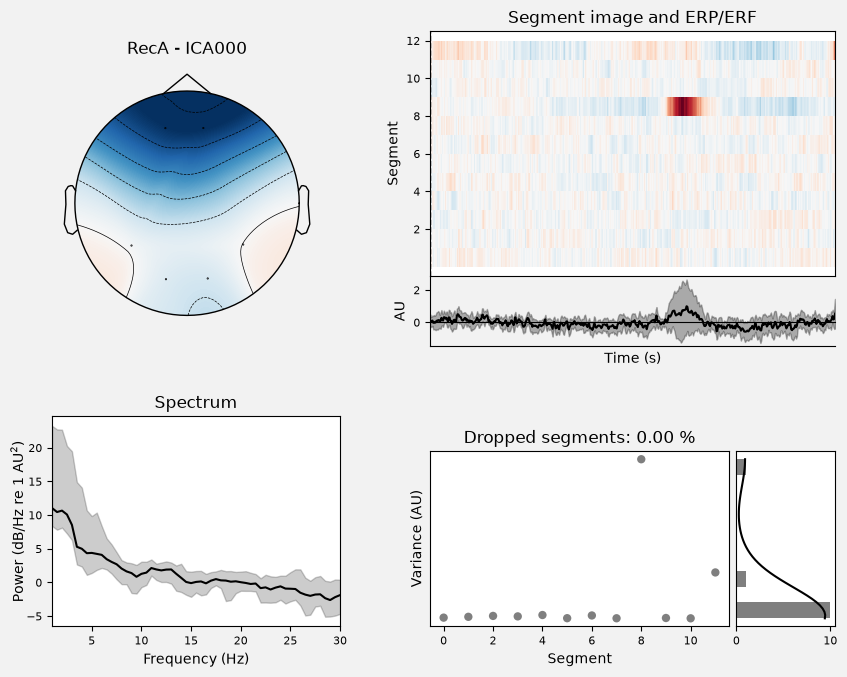

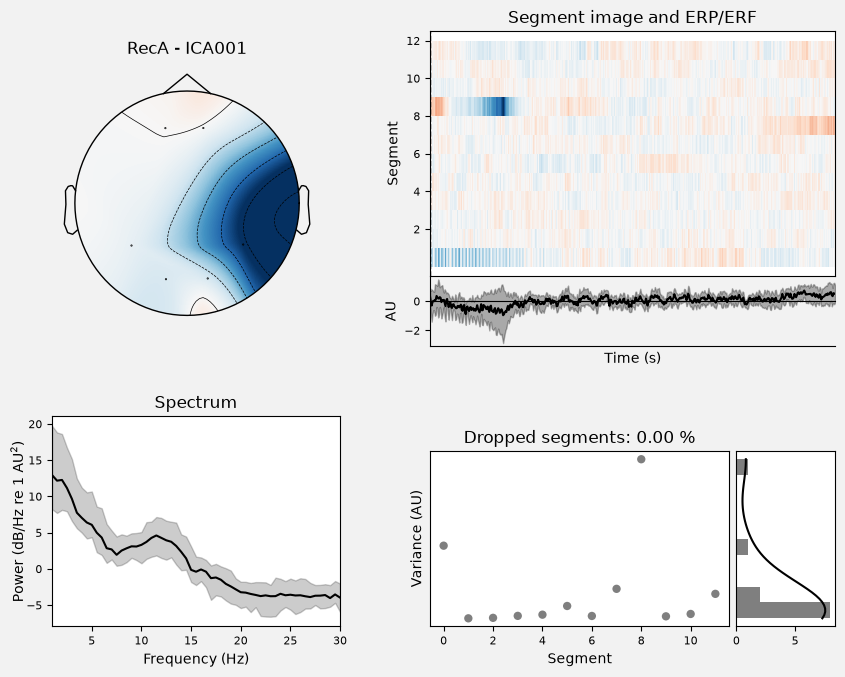

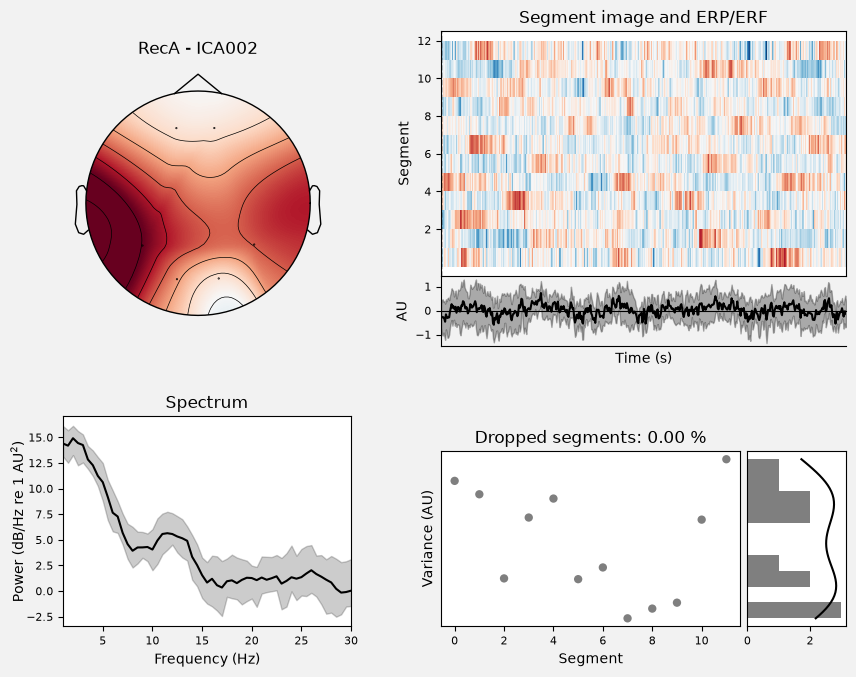

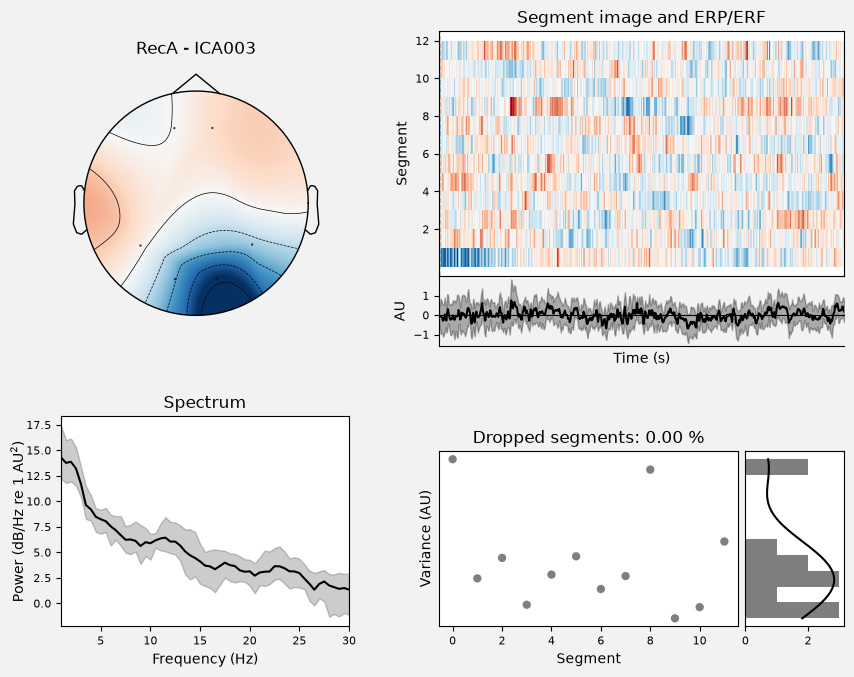

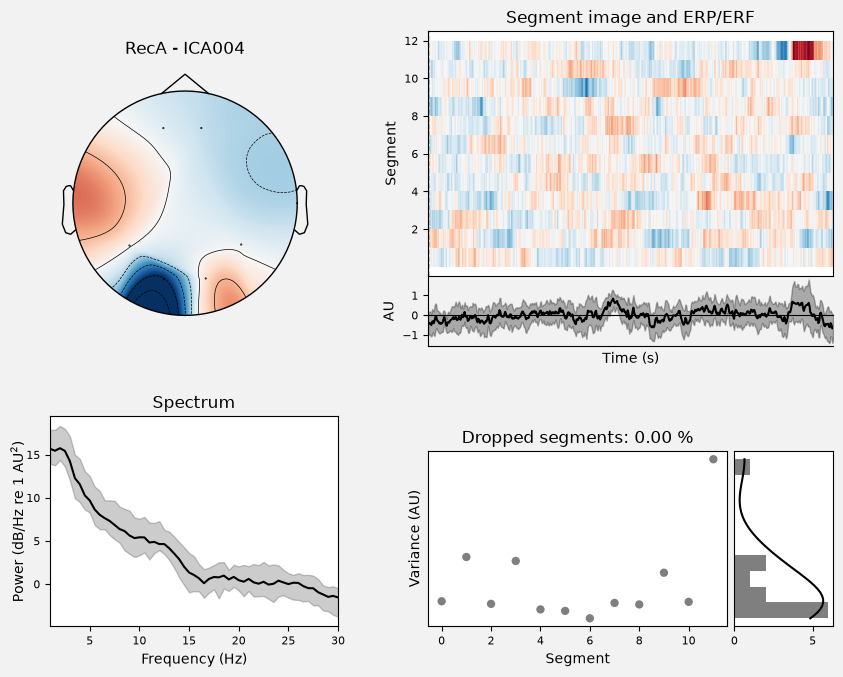

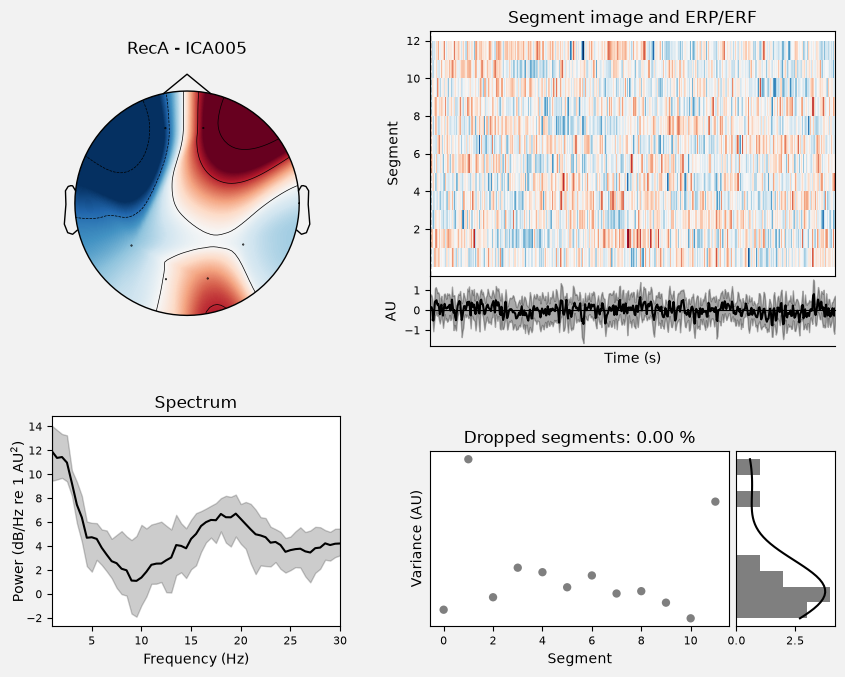

In [56]:
figures_a = ica_a.plot_properties(
    ica_data_a,
    picks=range(6),
    psd_args=dict(fmin=1, fmax=30),
    figsize=(9, 7),
    show=False
)

for component, fig in enumerate(figures_a):
    fig.axes[0].set_title(f"RecA - ICA{component:03d}")

plt.show()

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated


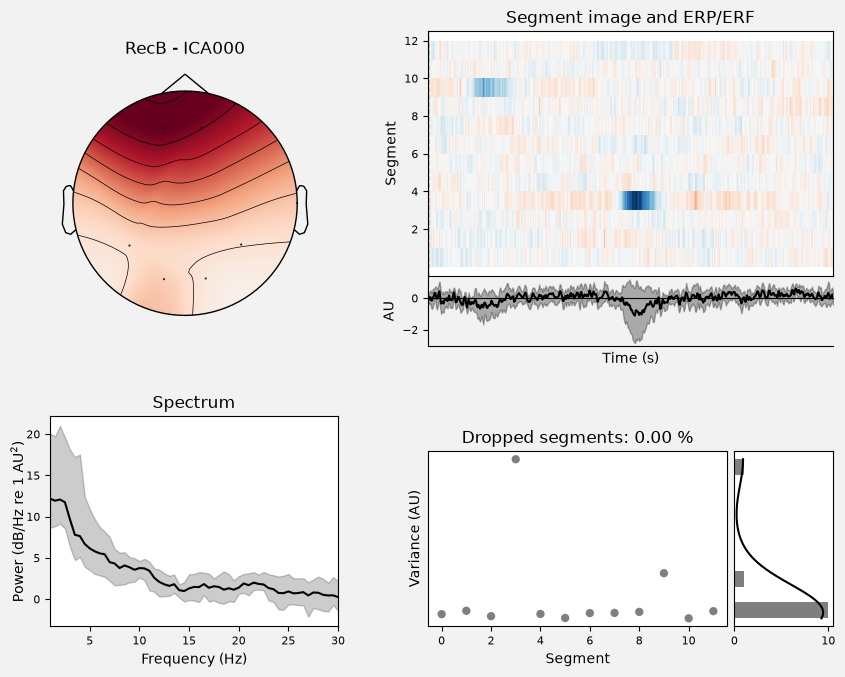

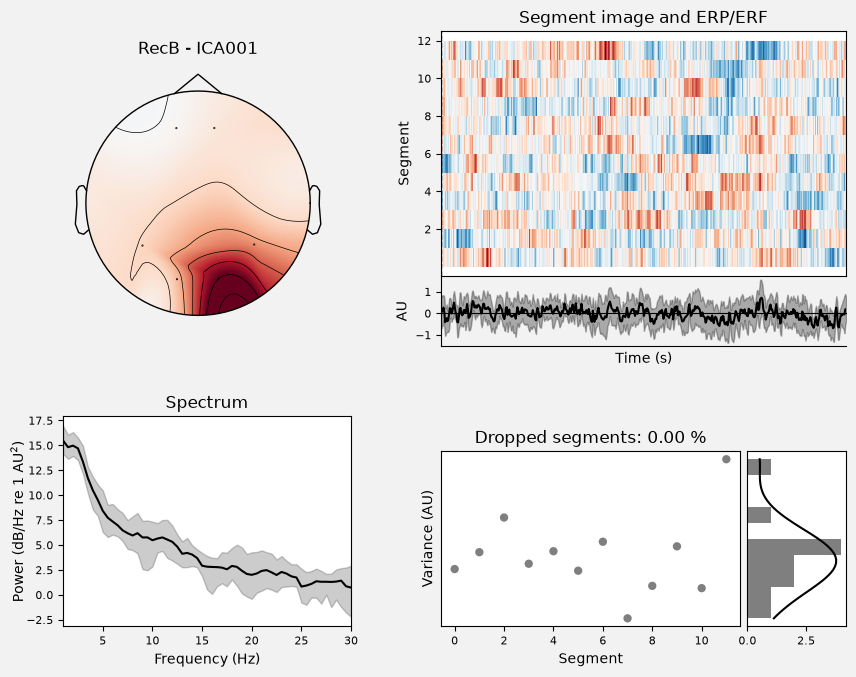

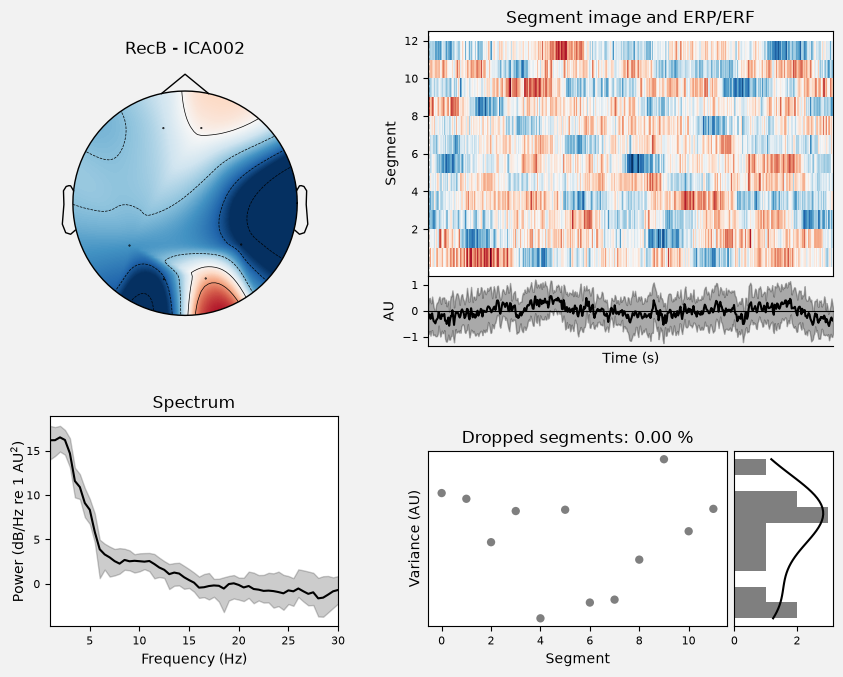

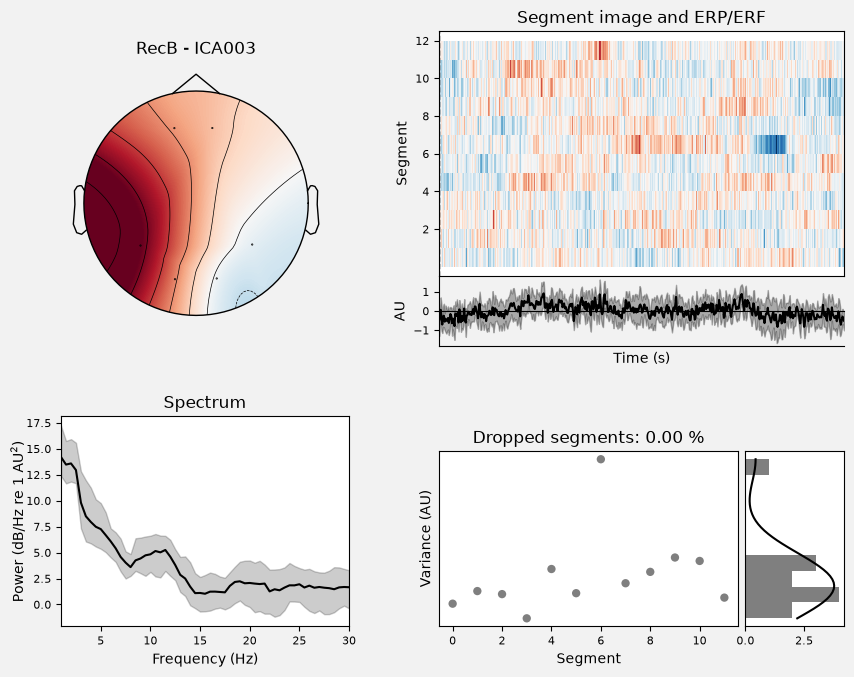

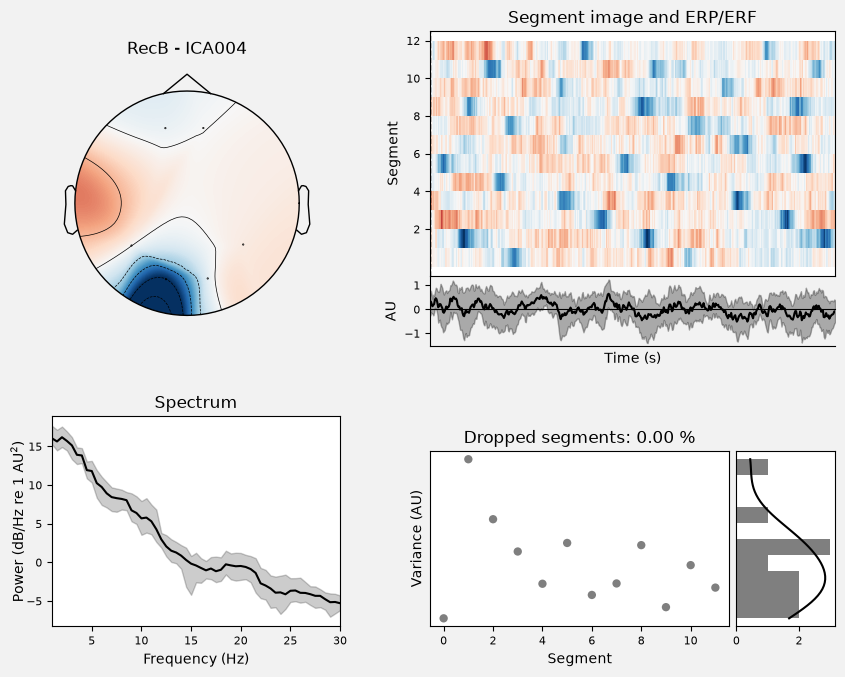

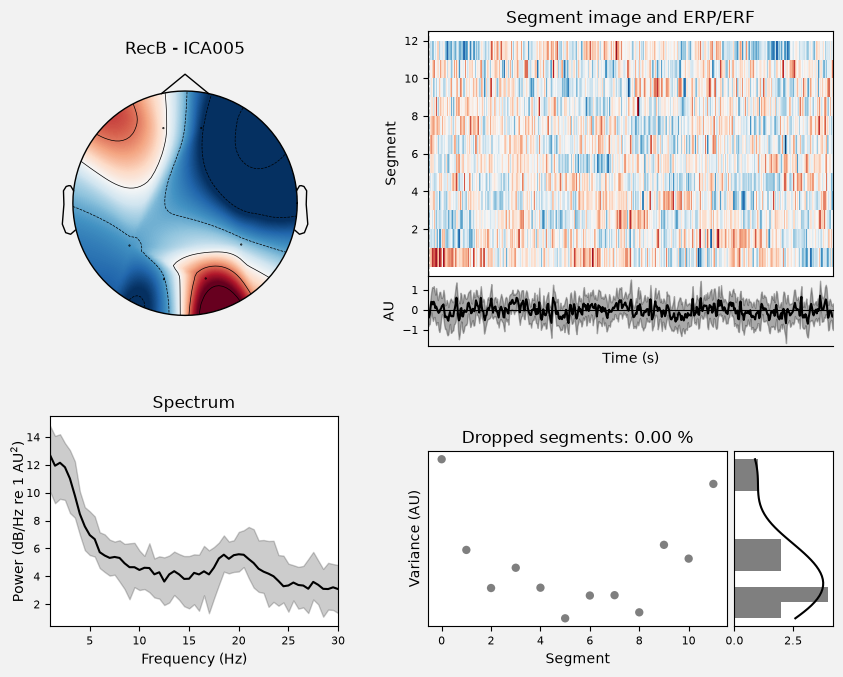

In [57]:
figures_b = ica_b.plot_properties(
    ica_data_b,
    picks=range(6),
    psd_args=dict(fmin=1, fmax=30),
    figsize=(9, 7),
    show=False
)

for component, fig in enumerate(figures_b):
    fig.axes[0].set_title(f"RecB - ICA{component:03d}")

plt.show()